In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Generate sample e-commerce order data

rng = np.random.default_rng(42)

n = 2000

orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") +
                  pd.to_timedelta(
                      rng.integers(0, 365, n),
                      unit="D"
                  ),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.30, 0.35, 0.20, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)
})

print("E-commerce dataset generated successfully!")

E-commerce dataset generated successfully!


In [3]:

# Display first five records

orders.head()

,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [4]:

print("Dataset Shape:", orders.shape)
print("Number of Rows:", orders.shape[0])
print("Number of Columns:", orders.shape[1])

Dataset Shape: (2000, 4)
Number of Rows: 2000
Number of Columns: 4


In [5]:

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   2000 non-null   datetime64[ns]
 1   customer_id  2000 non-null   int64         
 2   category     2000 non-null   object        
 3   amount       2000 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 62.6+ KB


In [6]:

orders.describe()

,order_date,customer_id,amount
count,2000,2000.000000,2000.000000
mean,2025-07-01 22:45:07.200000,151.195500,1202.116645
min,2025-01-01 00:00:00,1.000000,8.810000
25%,2025-03-31 18:00:00,74.000000,597.515000
50%,2025-07-02 00:00:00,149.000000,1005.870000
75%,2025-10-03 00:00:00,226.000000,1613.855000
max,2025-12-31 00:00:00,300.000000,6276.090000
std,NaN,86.210007,826.961568


In [7]:

print("Missing Values:")
print(orders.isnull().sum())

Missing Values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64


In [8]:

print("Duplicate Records:", orders.duplicated().sum())

Duplicate Records: 0


In [9]:

# Convert order_date into datetime format

orders["order_date"] = pd.to_datetime(orders["order_date"])

# Extract date features

orders["month"] = orders["order_date"].dt.to_period("M")

orders["weekday"] = orders["order_date"].dt.day_name()

orders["quarter"] = orders["order_date"].dt.quarter

# Display updated dataset

orders.head()

,order_date,customer_id,category,amount,month,weekday,quarter
0,2025-02-02,264,Home,391.13,2025-02,Sunday,1
1,2025-10-10,19,Fashion,2456.21,2025-10,Friday,4
2,2025-08-27,120,Books,674.90,2025-08,Wednesday,3
3,2025-06-10,138,Home,75.38,2025-06,Tuesday,2
4,2025-06-08,240,Electronics,774.42,2025-06,Sunday,2


In [10]:

# Calculate monthly revenue

monthly = orders.groupby("month")["amount"].sum()

print("Monthly Revenue:")
print(monthly.round(2))

Monthly Revenue:
month
2025-01    193341.87
2025-02    232027.20
2025-03    206327.14
2025-04    197310.20
2025-05    194090.49
2025-06    221889.83
2025-07    221813.81
2025-08    179783.75
2025-09    180569.95
2025-10    183418.13
2025-11    191512.71
2025-12    202148.21
Freq: M, Name: amount, dtype: float64


In [11]:

best_month = monthly.idxmax()
worst_month = monthly.idxmin()

print("Best Month:", best_month)
print("Highest Revenue:", round(monthly.max(), 2))

print("Worst Month:", worst_month)
print("Lowest Revenue:", round(monthly.min(), 2))


Best Month: 2025-02
Highest Revenue: 232027.2
Worst Month: 2025-08
Lowest Revenue: 179783.75


In [12]:

# Calculate monthly revenue growth

monthly_growth = monthly.pct_change() * 100

print("Monthly Revenue Growth:")
print(monthly_growth.round(2))

Monthly Revenue Growth:
month
2025-01      NaN
2025-02    20.01
2025-03   -11.08
2025-04    -4.37
2025-05    -1.63
2025-06    14.32
2025-07    -0.03
2025-08   -18.95
2025-09     0.44
2025-10     1.58
2025-11     4.41
2025-12     5.55
Freq: M, Name: amount, dtype: float64


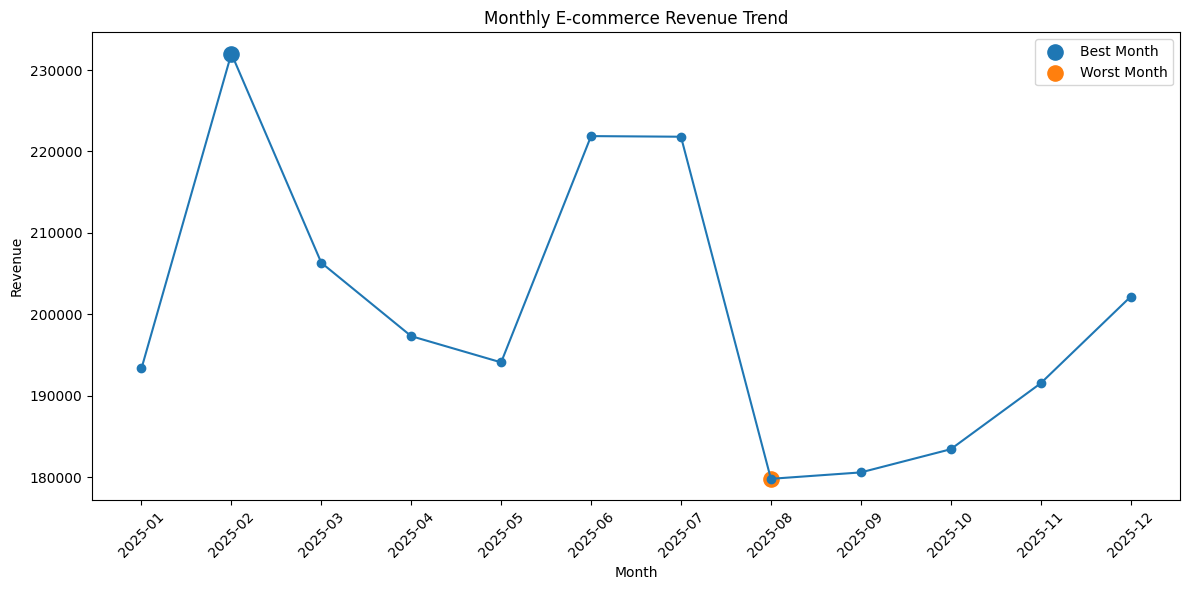

In [13]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly.index.astype(str),
    monthly.values,
    marker="o"
)

plt.title("Monthly E-commerce Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

# Highlight best and worst months

best_index = list(monthly.index).index(best_month)
worst_index = list(monthly.index).index(worst_month)

plt.scatter(
    best_index,
    monthly.loc[best_month],
    s=120,
    label="Best Month"
)

plt.scatter(
    worst_index,
    monthly.loc[worst_month],
    s=120,
    label="Worst Month"
)

plt.legend()
plt.tight_layout()
plt.show()

In [14]:

# Analyze category performance

by_category = orders.groupby("category")["amount"].agg(
    ["sum", "mean", "count"]
).sort_values("sum", ascending=False)

print(by_category.round(2))

                   sum     mean  count
category                              
Fashion      853984.93  1219.98    700
Electronics  722645.53  1163.68    621
Home         464114.66  1218.15    381
Books        363488.17  1219.76    298


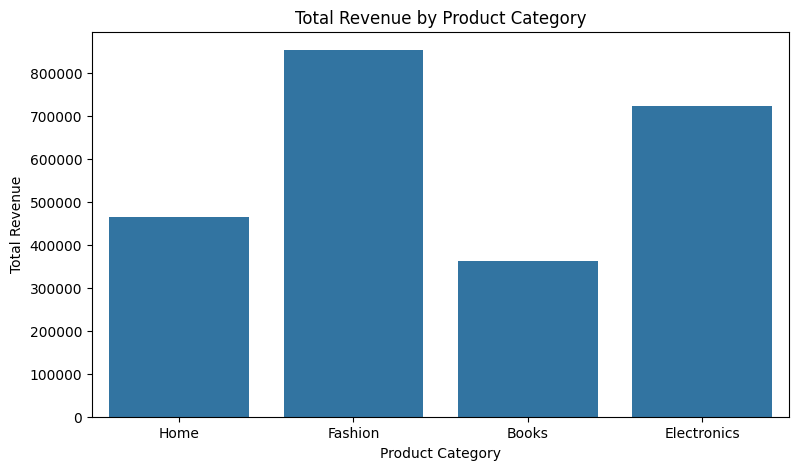

In [15]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=orders,
    x="category",
    y="amount",
    estimator="sum",
    errorbar=None
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.show()

In [16]:

# Create monthly category pivot table

pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    fill_value=0
)

print(pivot.round(2))

category     Books  Electronics   Fashion      Home
month                                              
2025-01   29186.89     62841.89  64665.99  36647.10
2025-02   34034.13     53564.89  86123.31  58304.87
2025-03   27843.58     58055.95  75138.67  45288.94
2025-04   26593.72     83335.56  57057.72  30323.20
2025-05   34425.63     57219.16  68569.90  33875.80
2025-06   32936.76     60037.00  85598.09  43317.98
2025-07   35582.36     72649.65  72647.96  40933.84
2025-08   32550.65     56690.46  71251.54  19291.10
2025-09   21824.73     60388.56  60231.75  38124.91
2025-10   23728.54     48799.72  70978.87  39911.00
2025-11   35826.81     51641.63  65122.45  38921.82
2025-12   28954.37     57421.06  76598.68  39174.10


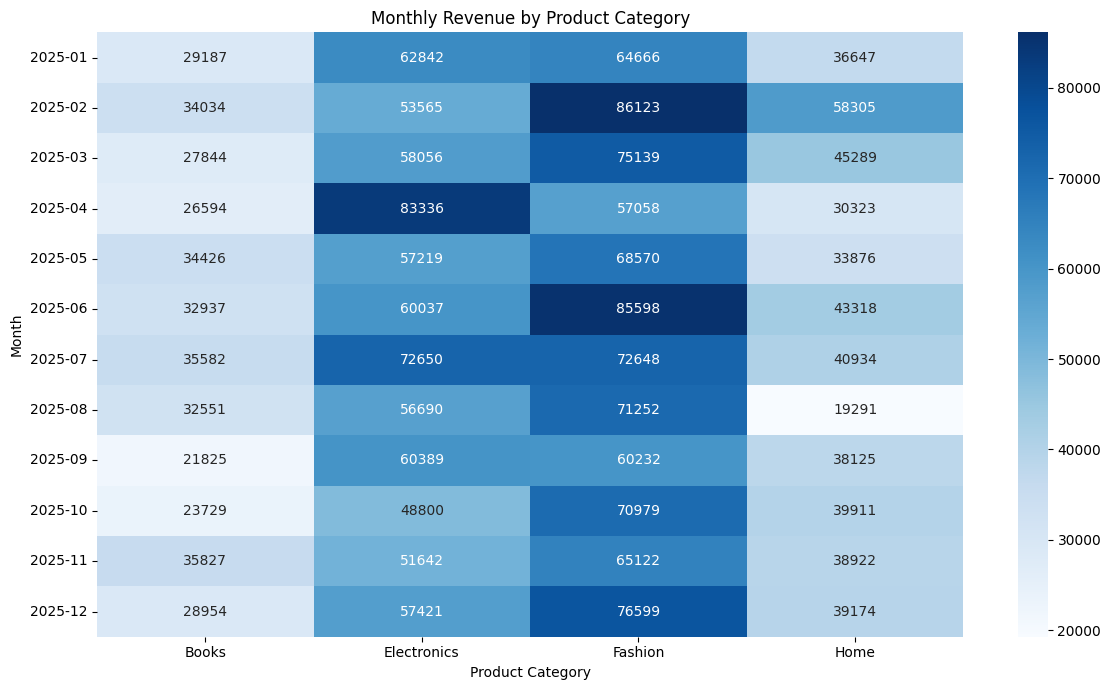

In [17]:

plt.figure(figsize=(12, 7))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Monthly Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [18]:

# Calculate total spending per customer

spend = orders.groupby("customer_id")["amount"].sum()

# Sort customers by spending

spend = spend.sort_values(ascending=False)

# Display top 10 customers

print("Top 10 Customers:")
print(spend.head(10).round(2))

Top 10 Customers:
customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64


In [19]:

# Calculate the number of top 10% customers

top_10_count = int(np.ceil(len(spend) * 0.10))

# Calculate their revenue

top_10_revenue = spend.head(top_10_count).sum()

# Calculate total revenue

total_revenue = spend.sum()

# Calculate revenue contribution percentage

top_share = (top_10_revenue / total_revenue) * 100

print("Total Customers:", len(spend))
print("Top 10% Customers:", top_10_count)
print("Top 10% Revenue:", round(top_10_revenue, 2))
print("Total Revenue:", round(total_revenue, 2))
print("Revenue Contribution:", round(top_share, 2), "%")

Total Customers: 300
Top 10% Customers: 30
Top 10% Revenue: 455331.97
Total Revenue: 2404233.29
Revenue Contribution: 18.94 %


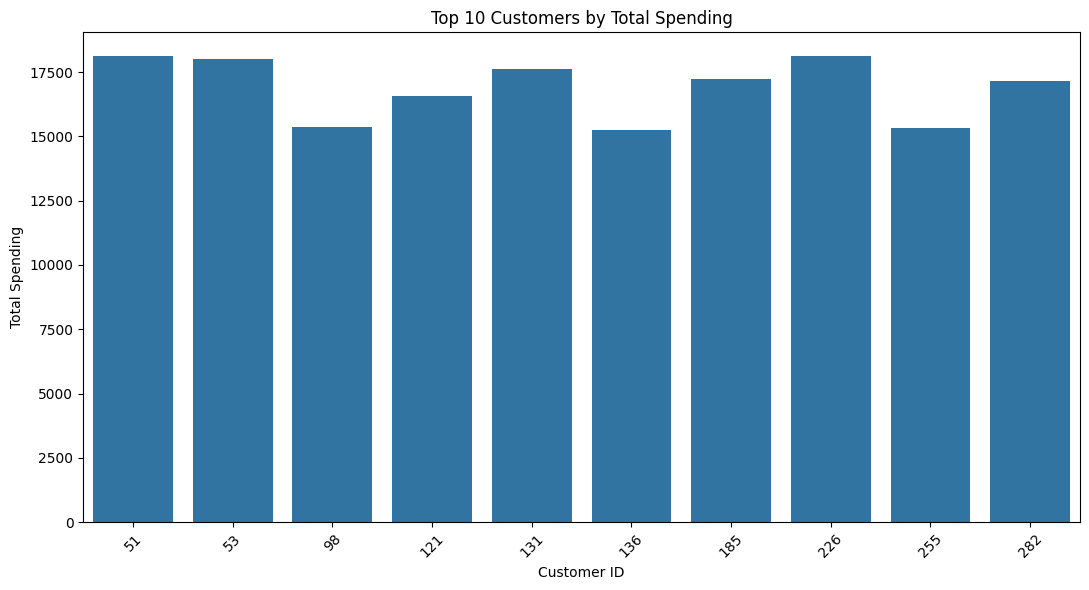

In [20]:

top_customers = spend.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_customers,
    x="customer_id",
    y="amount"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:

weekday_revenue = orders.groupby("weekday")["amount"].sum()

print("Revenue by Weekday:")
print(weekday_revenue.sort_values(ascending=False).round(2))

Revenue by Weekday:
weekday
Monday       370097.07
Wednesday    363020.15
Saturday     352097.65
Friday       349386.14
Tuesday      335978.37
Sunday       329908.31
Thursday     303745.60
Name: amount, dtype: float64


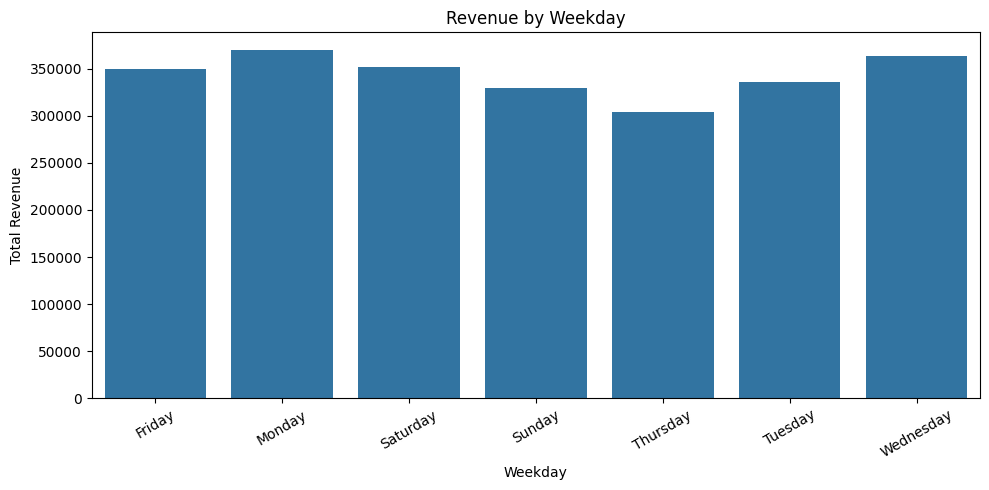

In [22]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_revenue.index,
    y=weekday_revenue.values
)

plt.title("Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Revenue")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:

quarterly_revenue = orders.groupby("quarter")["amount"].sum()

print("Quarterly Revenue:")
print(quarterly_revenue.round(2))

Quarterly Revenue:
quarter
1    631696.21
2    613290.52
3    582167.51
4    577079.05
Name: amount, dtype: float64


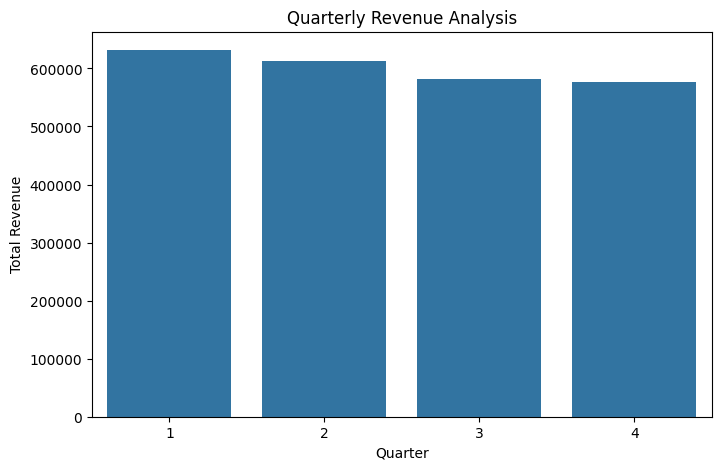

In [24]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=quarterly_revenue.index,
    y=quarterly_revenue.values
)

plt.title("Quarterly Revenue Analysis")
plt.xlabel("Quarter")
plt.ylabel("Total Revenue")

plt.show()

In [25]:

print("========== BUSINESS INSIGHTS ==========")

print(
    f"Best Revenue Month: {best_month} "
    f"with revenue {monthly.max():.2f}"
)

print(
    f"Worst Revenue Month: {worst_month} "
    f"with revenue {monthly.min():.2f}"
)

print(
    f"Top Product Category: {by_category.index[0]}"
)

print(
    f"Top 10% Customers contribute "
    f"{top_share:.2f}% of total revenue"
)

print("=======================================")

========== BUSINESS INSIGHTS ==========
Best Revenue Month: 2025-02 with revenue 232027.20
Worst Revenue Month: 2025-08 with revenue 179783.75
Top Product Category: Fashion
Top 10% Customers contribute 18.94% of total revenue


three business recommendations:

Customer loyalty: Provide loyalty rewards to the top 10% of customers to encourage repeat purchases.

Category strategy: Focus marketing campaigns on the category generating the highest revenue.



Monthly sales strategy: Investigate the best and worst performing months and plan targeted promotions for weaker months.

# E-Commerce Sales Trend Analysis

## 1. Context
This project analyzes a sample e-commerce sales dataset containing 2,000 orders and 300 customer IDs generated using Python.

The objective is to identify monthly revenue trends, top-performing product categories and valuable customers.

## 2. Key Findings
- Best revenue month: [Insert your result]
- Lowest revenue month: [Insert your result]
- Best-performing category: [Insert your result]
- Revenue contribution from the top 10% of customers: [Insert your result]
- Highest revenue weekday: [Insert your result]

## 3. Recommendations
1. Introduce loyalty rewards for high-value customers.
2. Focus marketing campaigns on the best-performing product category.
3. Plan targeted promotional campaigns during lower-revenue months.

## 4. Next Steps
- Monitor monthly sales performance.
- Track customer purchasing behavior.
- Evaluate the effectiveness of marketing campaigns.
- Collect real business data for future analysis.

## Tools Used
Python, Pandas, NumPy, Matplotlib and Seaborn.

## Dataset
Python-generated sample e-commerce order data.

In [26]:

# Save generated dataset

orders.to_csv("ecommerce_sales_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [27]:

monthly_report = monthly.to_frame(name="total_revenue")

monthly_report.to_csv("monthly_revenue_report.csv")

print("Monthly revenue report saved!")

Monthly revenue report saved!


In [28]:
from google.colab import files

files.download("ecommerce_sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
files.download("monthly_revenue_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>